# T04 · Réseaux convolutifs (CNN) pour la cybersécurité — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Maîtriser l'opération de convolution (stride, padding, taille de sortie) et le pooling max, source d'invariance translationnelle
- Comprendre l'anatomie d'un CNN (blocs convolutionnels, champ récepteur) et son avantage en paramètres face à un MLP
- Écrire un mini-CNN complet en numpy (im2col + rétropropagation à la main), le **vérifier par gradient check** et l'entraîner sur des « images de malware » synthétiques

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil |
|---|---|
| Classifier des « images de bytes » de malware (MalwareNet, N-gram images) | CNN sur matrices 2-D (P6, P7) |
| Signatures qui se déplacent dans le trafic (paquets, séquences d'octets) | Pooling = invariance translationnelle (P2) |
| Interpréter ce que détecte un classifieur de fichiers | Filtres & cartographies de caractères (P5) |
| Détecteur léger embarquable (sonde IDS, endpoint) | Compte de paramètres CNN ≪ MLP (P4) |
| Faire confiance au backward de son détecteur | Gradient check im2col (P6) |

**Pré-requis :** T01 (rétropropagation d'un MLP, gradient check), produit de Hadamard, `numpy`. *(réf. Goodfellow ch. 9)*

> 💡 *Conseil étude* : prédisez la taille de sortie `out = ⌊(n + 2p − k)/s⌋ + 1` avant
> chaque cellule, puis vérifiez. Le CNN de la P6 est écrit **entièrement à la main** :
> le gradient check n'est pas un ornement, c'est lui qui valide votre backward.


## 📌 Bloc 0 — Environnement & imports
Installez le stack si besoin (déjà pré-installé sur Colab).
Chaque notebook contient des sorties pré-calculées : vous pouvez les relire
sans rien exécuter, ou « Run All » pour reproduire.

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score
np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · L'opération de convolution : stride, padding, taille de sortie

### Ce qu'on apprend
Une couche convolutive pose un **noyau** (filtre) $W \in \mathbb{R}^{k \times k}$ sur
chaque fenêtre glissante de l'entrée et calcule un produit scalaire patch · noyau.
À chaque position de sortie :

```
out[i, j] = Σ_u Σ_v  patch[i·s+u, j·s+v] · W[u, v]      (s = stride)
```

Taille de sortie, **la formule à ne jamais rater** :

```
out = ⌊(n + 2p − k) / s⌋ + 1
```

- `n` taille d'entrée, `k` taille de noyau, `p` padding, `s` stride.
- **padding** `p = (k−1)/2` (k impair, s=1) → « same » : la sortie garde la taille de l'entrée.
- **stride** `s = 2` → division (environ) par 2 de la résolution.

### Piège classique
Oublier le **plancher** : `(16 + 2·1 − 3)/3 = 5` exactement (sortie 6), mais `(16 − 3)/2 = 6.5 → ⌊6.5⌋+1 = 7`,
pas 7.5. Une mauvaise taille de sortie se paie en `ShapeError` au premier entraînement —
ou pire, en reshape silencieux qui mélange les pixels.


In [2]:
def conv_output_size(n, k, s=1, p=0):
    """Output spatial size of one conv layer: floor((n + 2p - k)/s) + 1."""
    return (n + 2 * p - k) // s + 1

def conv2d_naive(img, kern, stride=1, pad=0):
    """Single-channel 2-D cross-correlation with a square kernel (teaching version)."""
    H, W = img.shape
    k = kern.shape[0]
    if pad:
        img = np.pad(img, pad)
    oh = conv_output_size(H, k, stride, pad)
    ow = conv_output_size(W, k, stride, pad)
    out = np.zeros((oh, ow))
    for i in range(oh):
        for j in range(ow):
            patch = img[i*stride:i*stride+k, j*stride:j*stride+k]
            out[i, j] = (patch * kern).sum()
    return out

# The kernel placed on a delta image reproduces itself at the output (cross-correlation).
kern3 = np.arange(9.).reshape(3, 3)
img_delta = np.zeros((7, 7)); img_delta[3, 3] = 1.0
o = conv2d_naive(img_delta, kern3, stride=1, pad=0)
print("conv(delta, kernel 1..9) :", o.shape, "- valeur centrale =", o[2, 2])

# Verify the output-size formula on a grid of (n, k, s, p).
grid = [(16,3,1,1), (16,3,2,0), (16,5,1,2), (16,3,3,1), (8,3,2,1), (7,4,2,0), (10,5,1,0), (16,7,1,3)]
for (n, k, s, p) in grid:
    rng = np.random.default_rng(0)
    im = rng.normal(size=(n, n)); kk = rng.normal(size=(k, k))
    got = conv2d_naive(im, kk, s, p).shape[0]
    print(f"n={n:2d} k={k} s={s} p={p} -> formule {conv_output_size(n,k,s,p):2d} | réel {got:2d}")

conv(delta, kernel 1..9) : (5, 5) - valeur centrale = 4.0
n=16 k=3 s=1 p=1 -> formule 16 | réel 16
n=16 k=3 s=2 p=0 -> formule  7 | réel  7
n=16 k=5 s=1 p=2 -> formule 16 | réel 16
n=16 k=3 s=3 p=1 -> formule  6 | réel  6
n= 8 k=3 s=2 p=1 -> formule  4 | réel  4
n= 7 k=4 s=2 p=0 -> formule  2 | réel  2
n=10 k=5 s=1 p=0 -> formule  6 | réel  6
n=16 k=7 s=1 p=3 -> formule 16 | réel 16


### Exercice corrigé

In [3]:
# ---- Exercice P1 : formule de taille de sortie vérifiée numériquement ----
# 1) Values probed by running conv2d_naive on a grid of (n, k, s, p).
assert conv_output_size(16, 3, 1, 1) == 16
assert conv_output_size(16, 3, 2, 0) == 7          # floor((16-3)/2)+1 = 7, not 6.5
assert conv_output_size(16, 3, 3, 1) == 6
assert conv_output_size(16, 7, 1, 3) == 16          # 'same' with k=7
assert conv_output_size(7, 4, 2, 0) == 2            # even kernel, floor bites

# 2) Formula must match the real loop-based convolution everywhere.
rng = np.random.default_rng(0)
for (n, k, s, p) in grid:
    im = rng.normal(size=(n, n)); kk = rng.normal(size=(k, k))
    exp = conv_output_size(n, k, s, p)
    assert conv2d_naive(im, kk, s, p).shape == (exp, exp)

# 3) Convolution of a delta reproduces the kernel (probed: center 4.0, sum 36.0).
assert o.shape == (5, 5) and o[2, 2] == 4.0 and o.sum() == 36.0
print("Exercice P1 vérifié : formule ⌊(n+2p−k)/s⌋+1 conforme à la boucle réelle.")

Exercice P1 vérifié : formule ⌊(n+2p−k)/s⌋+1 conforme à la boucle réelle.


## 2 · Pooling & invariance translationnelle

### Ce qu'on apprend
Le **max-pooling** découpe la carte en fenêtres $f \times f$ (typ. 2×2, stride = f)
et ne garde que le maximum de chaque fenêtre. Résultat : moitié de résolution,
moitié de calculs — et surtout une **invariance (quasi) translationnelle** :

- un pic de réponse qui se déplace de 1–2 pixels **dans la même fenêtre** de pooling
  laisse la sortie **inchangée** ;
- la sensibilité reste sur la **présence** du motif, pas sur sa position exacte.

En cyber : une signature (suite d'octets, motif de bytes) qui apparaît décalée de
quelques octets dans la fenêtre analysée produit la même cartographie poolée.

### Piège classique
Le max-pooling n'est invariant qu'aux translations **inférieures à la fenêtre** et
**alignées** : un décalage qui change la réponse de fenêtre la modifie. Et un
average-pooling, lui, **dilue** un pic isolé — pour détecter la *présence* d'un
motif rare, le max est bien plus adapté.


maxpool 2x2 de arange(16):
 [[ 5.  7.]
 [13. 15.]]
backward : somme des gradients = 4.0 - pixels non nuls = 4
décalage d'un pixel : L1 brut = 2.0, L1 après maxpool = 0.0


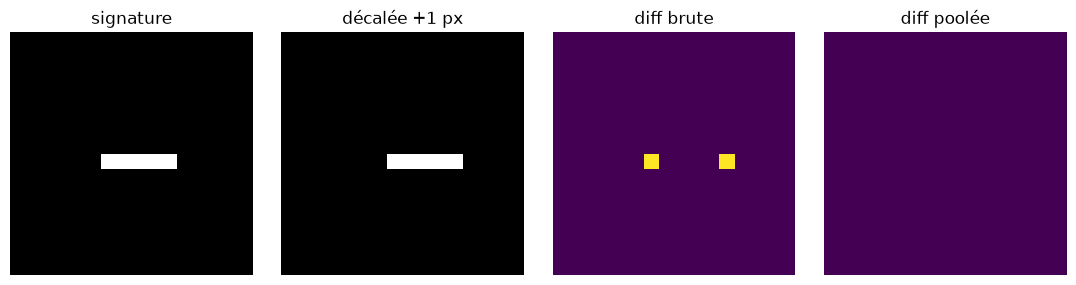

In [4]:
def maxpool_forward2(x, size=2):
    """Max-pool (n,C,h,w)->(n,C,h/f,w/f); mask routes gradient UNIFORMLY across ties."""
    n, c, h, w = x.shape
    oh, ow = h // size, w // size
    out = np.zeros((n, c, oh, ow))
    mask = np.zeros_like(x, dtype=float)
    for oi in range(oh):
        for oj in range(ow):
            sl = (slice(None), slice(None), slice(oi*size, (oi+1)*size), slice(oj*size, (oj+1)*size))
            block = x[sl]
            mx = block.max(axis=(2, 3))
            out[:, :, oi, oj] = mx
            m = (block == mx[:, :, None, None])
            mask[sl] = m / m.sum(axis=(2, 3), keepdims=True)
    return out, mask

def maxpool_backward(dout, mask, size=2):
    """Route upstream gradient back through the forward mask."""
    n, c, _, _ = dout.shape
    h, w = mask.shape[2], mask.shape[3]
    dx = np.zeros_like(mask, dtype=float)
    for oi in range(h // size):
        for oj in range(w // size):
            dx[:, :, oi*size:(oi+1)*size, oj*size:(oj+1)*size] = (
                dout[:, :, oi, oj][:, :, None, None] * mask[:, :, oi*size:(oi+1)*size, oj*size:(oj+1)*size])
    return dx

# Pooling of a known 4x4 block: max of each quadrant (probed: [[5,7],[13,15]]).
x44 = np.arange(16, dtype=float).reshape(1, 1, 4, 4)
p44, mask44 = maxpool_forward2(x44, 2)
print("maxpool 2x2 de arange(16):\n", p44[0, 0])

# Gradient conservation: d(sum of pooled outputs) w.r.t input sums to 4 (one per window).
d = np.ones((1, 1, 2, 2))
dx = maxpool_backward(d, mask44, 2)
print("backward : somme des gradients =", dx.sum(), "- pixels non nuls =", int((dx > 0).sum()))

# Translation invariance on a 'signature' bar shifted by one pixel.
def bar_image(r0, c0, horiz):
    img = np.zeros((16, 16))
    if horiz: img[r0, c0:c0+5] = 1.0
    else: img[r0:r0+5, c0] = 1.0
    return img

im1 = bar_image(8, 6, True)
im2 = np.roll(im1, 1, axis=1)               # shift right by 1 px (signature moved)
p1, _ = maxpool_forward2(im1[None, None], 2)
p2, _ = maxpool_forward2(im2[None, None], 2)
raw_l1 = np.abs(im1 - im2).sum()
pool_l1 = np.abs(p1 - p2).sum()
print(f"décalage d'un pixel : L1 brut = {raw_l1}, L1 après maxpool = {pool_l1}")

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8))
axes[0].imshow(im1, cmap="gray"); axes[0].set_title("signature")
axes[1].imshow(im2, cmap="gray"); axes[1].set_title("décalée +1 px")
axes[2].imshow(np.abs(im1 - im2), cmap="viridis"); axes[2].set_title("diff brute")
axes[3].imshow(np.abs(p1[0, 0] - p2[0, 0]), cmap="viridis"); axes[3].set_title("diff poolée")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

### Exercice corrigé

In [5]:
# ---- Exercice P2 : pooling correct et invariance translationnelle mesurée ----
# 1) Max of each quadrant of arange(16) (probed values).
assert p44.shape == (1, 1, 2, 2)
assert np.array_equal(p44[0, 0], np.array([[5., 7.], [13., 15.]]))

# 2) Backward routes gradient to the argmax pixels only; total gradient conserved.
assert dx.sum() == 4.0                      # one unit routed per 2x2 window
assert int((dx > 0).sum()) == 4

# 3) Resolution halved on the 16x16 input.
assert p1.shape == (1, 1, 8, 8)

# 4) Translation by 1 px: raw representation changes, pooled one does not (probed 2.0 vs 0.0).
assert raw_l1 == 2.0 and pool_l1 == 0.0
assert pool_l1 < raw_l1
print("Exercice P2 vérifié : maxpool exact, backward conservé, signature décalée indétectable.")

Exercice P2 vérifié : maxpool exact, backward conservé, signature décalée indétectable.


## 3 · Anatomie d'un CNN : blocs et champ récepteur

### Ce qu'on apprend
Un CNN moderne empile des **blocs** `[Conv → ReLU] × n → Pool` puis un
`Flatten → Dense → Softmax` pour la classification. *(réf. Goodfellow ch. 9)*

Le **champ récepteur** (receptive field) est la taille de la région de l'image
d'origine qui influence un neurone de la couche considérée. Il se calcule en
remontant les couches avec le **saut** (jump) cumulé :

```
RF ← RF + (k − 1) × jump        et        jump ← jump × s
```

Exemple (notre mini-CNN) : `Conv(3×3,s1) → Pool(2,s2) → Conv(3×3,s1) → Pool(2,s2)`
donne `RF = 1+2·1 +1·1 +2·2 +1·2 = 10` pixels avec un saut de 4 : chaque neurone
« voit » une fenêtre de 10×10 de l'image d'origine — exactement la taille d'une
signature de bytes.

### Piège classique
Croire qu'un neurone de couche profonde « voit » 3×3 pixels : chaque convolution
ne voit que 3×3 de sa **couche précédente**, mais la récursion élargit vite.
Un champ récepteur trop petit pour la taille de la signature = motifs manqués.


In [6]:
def receptive_field(layers):
    """Recursive receptive field; layers = list of (kernel_size, stride) in order."""
    rf, jump = 1, 1
    for k, s in layers:
        rf += (k - 1) * jump
        jump *= s
    return rf, jump

print("3 x Conv(3x3,s1)           -> RF, jump =", receptive_field([(3, 1)] * 3))
print("Conv-Pool-Conv-Pool (notre) -> RF, jump =", receptive_field([(3, 1), (2, 2), (3, 1), (2, 2)]))

# Numerical check: an impulse sent through 3 valid 3x3 convs (positive kernels + ReLU)
# influences exactly a (2*3+1) x (2*3+1) region of the final map.
rng = np.random.default_rng(7)
img = np.zeros((21, 21)); img[10, 10] = 1.0
kerns = [np.abs(rng.normal(size=(3, 3))) + 0.05 for _ in range(3)]
o_imp = img
for kk in kerns:
    o_imp = np.maximum(conv2d_naive(o_imp, kk, 1, 0), 0.0)
nz = np.argwhere(o_imp > 0)
print("impulsion : pixels d'entrée influencés en sortie -> bbox", nz.max(0) - nz.min(0) + 1,
      "- nb de pixels =", len(nz))

3 x Conv(3x3,s1)           -> RF, jump = (7, 1)
Conv-Pool-Conv-Pool (notre) -> RF, jump = (10, 4)
impulsion : pixels d'entrée influencés en sortie -> bbox [7 7] - nb de pixels = 49


### Exercice corrigé

In [7]:
# ---- Exercice P3 : champ récepteur calculé = champ récepteur mesuré ----
# 1) Formula values (probed).
assert receptive_field([(3, 1)] * 3) == (7, 1)
assert receptive_field([(3, 1), (2, 2), (3, 1), (2, 2)]) == (10, 4)

# 2) The impulse experiment shows exactly the same footprint (probed: 7x7, 49 px).
assert (nz.max(0) - nz.min(0) + 1).tolist() == [7, 7]
assert len(nz) == 49
print("Exercice P3 vérifié : RF calculé (7, jump 1) == RF mesuré (bbox 7x7, 49 px).")

Exercice P3 vérifié : RF calculé (7, jump 1) == RF mesuré (bbox 7x7, 49 px).


## 4 · Compte de paramètres : CNN vs MLP

### Ce qu'on apprend
Le gain fondamental de la convolution est le **partage de poids** (*weight sharing*) :
un même noyau glisse sur toute l'image, alors qu'un MLP dense attache un poids
distinct à chaque connexion pixel-neurone.

| Couche | Paramètres |
|---|---|
| Conv (F filtres k×k, C canaux d'entrée) | `F·k·k·C + F` |
| Dense (nᵢₙ → nₒᵤₜ) | `nᵢₙ·nₒᵤₜ + nₒᵤₜ` |

Notre mini-CNN sur images 16×16 : `Conv(2 filtres 3×3) → Pool → Dense(128→8) → Dense(8→2)`
= **1 070 paramètres**. Le MLP équivalent `Dense(256→64) → Dense(64→2)` en compte
**16 578**, soit ~15× de plus — à capacité de détection comparable sur des motifs
locaux. Une sonde IDS embarquée y gagne en RAM, en vitesse et en risque de sur-apprentissage.

### Piège classique
Oublier les **biais** (`+F`, `+n_out`) dans le compte — ou oublier le facteur
**canaux d'entrée** : un filtre 3×3 sur une image RGB fait 3·3·3 = 27 poids, pas 9.


In [8]:
def count_conv(F, C, k):
    """Conv layer params: F kernels of k*k over C input channels + F biases."""
    return F * C * k * k + F

def count_dense(nin, nout):
    """Dense layer params: weights + biases."""
    return nin * nout + nout

# Our tiny CNN (used in P6): Conv(2 filters 3x3, 1 chan) -> Pool -> Dense(128->8) -> Dense(8->2).
CNN_ARCH = [count_conv(2, 1, 3), count_dense(2 * 8 * 8, 8), count_dense(8, 2)]
n_cnn = sum(CNN_ARCH)
# Dense-equivalent baseline (used in P7): Dense(256->64) -> Dense(64->2).
MLP_ARCH = [count_dense(256, 64), count_dense(64, 2)]
n_mlp = sum(MLP_ARCH)
print("mini-CNN :", CNN_ARCH, "total =", n_cnn)
print("MLP 256-64-2 :", MLP_ARCH, "total =", n_mlp)
print(f"le MLP dense paye {n_mlp / n_cnn:.1f}x plus de paramètres qu'un CNN sur le même problème")

mini-CNN : [20, 1032, 18] total = 1070
MLP 256-64-2 : [16448, 130] total = 16578
le MLP dense paye 15.5x plus de paramètres qu'un CNN sur le même problème


### Exercice corrigé

In [9]:
# ---- Exercice P4 : comptes de paramètres exacts (valeurs sondées) ----
assert count_conv(2, 1, 3) == 20            # 2*1*3*3 + 2
assert count_dense(128, 8) == 1032
assert count_dense(8, 2) == 18
assert n_cnn == 1070
assert n_mlp == 16578
assert n_mlp > 15 * n_cnn
# The real tensor sizes of the P6 model will match this count exactly (checked in P6).
print("Exercice P4 vérifié : 1 070 paramètres CNN vs 16 578 MLP sur images 16x16.")

Exercice P4 vérifié : 1 070 paramètres CNN vs 16 578 MLP sur images 16x16.


## 5 · Filtres & cartographies de caractères (interprétabilité)

### Ce qu'on apprend
Un filtre 3×3 n'est rien d'autre qu'un **détecteur de motif local** :

- noyau de Sobel vertical → réagit aux **contours verticaux** ;
- noyau tout-1 → détecteur de **région claire** ;
- un filtre **appris** devient un détecteur de motif statistique (ici : barre horizontale vs verticale).

La **cartographie de caractères** (feature map) est la réponse du filtre en chaque
position : ses pics disent *où* le motif est présent. Visualiser filtres et
cartographies, c'est pouvoir **expliquer** un détecteur en soutenance — et repérer
qu'un modèle triche (il répond au bruit de fond, pas au motif).

### Piège classique
Regarder les poids d'un filtre au lieu de sa **cartographie d'activation** sur de
vraies entrées. Un filtre aux poids impressionnants peut ne répondre à rien ;
l'interprétation se fait sur les activations.


|réponse Sobel-x| max = 3.0 à la colonne 7
Sobel-y (image à contour horizontal) : max = 3.0 à la ligne 7
filtre tout-1 sur image pleine de 1 : réponse intérieure = 9.0


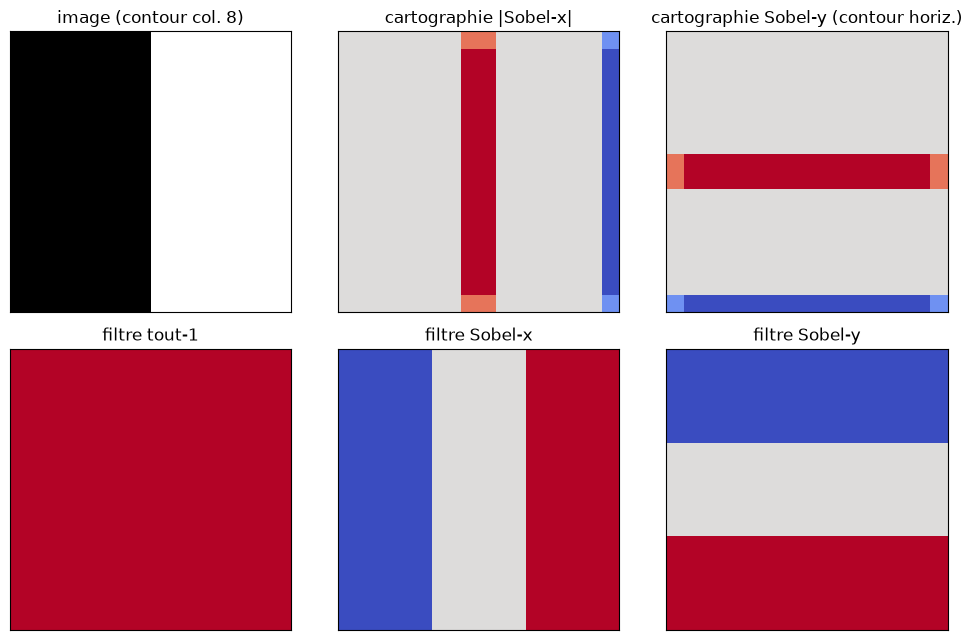

In [10]:
# Hand-crafted filters on a synthetic 'image' with a vertical edge at column 8.
test_img = np.zeros((16, 16)); test_img[:, 8:] = 1.0
sobel_x = np.array([[-1., 0., 1.], [-1., 0., 1.], [-1., 0., 1.]])
sobel_y = np.array([[-1., -1., -1.], [0., 0., 0.], [1., 1., 1.]])
r_x = conv2d_naive(test_img, sobel_x, 1, 1)
r_y = conv2d_naive(test_img, sobel_y, 1, 1)
test_img_h = np.zeros((16, 16)); test_img_h[8:, :] = 1.0   # horizontal edge at row 8
r_yh = conv2d_naive(test_img_h, sobel_y, 1, 1)
print("|réponse Sobel-x| max =", np.abs(r_x).max(), "à la colonne", np.abs(r_x).max(axis=0).argmax())
print("Sobel-y (image à contour horizontal) : max =", np.abs(r_yh).max(), "à la ligne", np.abs(r_yh).max(axis=1).argmax())

# A learned-like filter (all ones) is a plain 'bright region' detector.
ones_map = conv2d_naive(np.ones((16, 16)), np.ones((3, 3)), 1, 1)
print("filtre tout-1 sur image pleine de 1 : réponse intérieure =", ones_map[1, 1])

fig, axes = plt.subplots(2, 3, figsize=(10, 6.5))
axes[0, 0].imshow(test_img, cmap="gray"); axes[0, 0].set_title("image (contour col. 8)")
axes[0, 1].imshow(r_x, cmap="coolwarm", vmin=-3, vmax=3); axes[0, 1].set_title("cartographie |Sobel-x|")
axes[0, 2].imshow(r_yh, cmap="coolwarm", vmin=-3, vmax=3); axes[0, 2].set_title("cartographie Sobel-y (contour horiz.)")
for i, (im, t) in enumerate([(np.ones((3, 3)), "filtre tout-1"), (sobel_x, "filtre Sobel-x"), (sobel_y, "filtre Sobel-y")]):
    axes[1, i].imshow(im, cmap="coolwarm", vmin=-1, vmax=1)
    axes[1, i].set_title(t); axes[1, i].grid(False)
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### Exercice corrigé

In [11]:
# ---- Exercice P5 : lire une cartographie de caractères ----
# Sobel-x fires on the vertical edge: peak value 3.0 (3 rows x +1) at column 7 (probed).
assert r_x.shape == (16, 16)
assert np.abs(r_x).max() == 3.0
assert np.abs(r_x).max(axis=0).argmax() == 7
# Sobel-y is blind (interior) to a vertical edge, but fires on a horizontal one.
assert np.abs(r_y[1:15]).max() == 0.0          # interior: no vertical-edge response in y
assert np.abs(r_yh).max() == 3.0               # probed: peak 3.0 at row 7 (probed)
assert np.abs(r_yh).max(axis=1).argmax() == 7
# 'Bright region' filter: interior of an all-ones image = 9 = sum of the 3x3 kernel.
assert ones_map[1, 1] == 9.0
print("Exercice P5 vérifié : pics de cartographie aux vrais contours (col 7 / ligne 7).")

Exercice P5 vérifié : pics de cartographie aux vrais contours (col 7 / ligne 7).


## 6 · Cas cyber : classifier des « images de malware » avec un mini-CNN

### Le problème
On transforme des échantillons en **images 16×16** (comme les *byte-images* de
MalwareNet) : le trafic/code bénin présente des textures locales **horizontales**
(boucles d'octets répétées), le malware des textures **verticales** (en-têtes
structurés, paquets alignés). Les motifs sont **placés aléatoirement** : le
détecteur doit être translation-invariant — exactement ce que le CNN sait faire.

Architecture (1 070 paramètres, annoncés en P4) :

```
(16,16,1) → Conv 2 filtres 3×3 (pad 1) → ReLU → MaxPool 2×2 → (8,8,2)
          → Flatten(128) → Dense(8) ReLU → Dense(2) → Softmax + entropie croisée
```

Tout est écrit à la main : `im2col` pour la convolution avant, `col2im` pour le
rétro-gradient, backward complet, puis **gradient check contre les dérivées
numériques** — la seule façon de prouver qu'on n'a pas oublié un ⊙ ReLU′(z) en route.


In [12]:
# ---- im2col machinery: vectorized conv forward/backward ----
def im2col(x, k, stride=1, pad=0):
    """x (n,c,h,w) -> cols (k*k*c, n*oh*ow); row order ((ci*k+ki)*k+kj)."""
    n, c, h, w = x.shape
    oh = conv_output_size(h, k, stride, pad)
    ow = conv_output_size(w, k, stride, pad)
    xp = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad))) if pad else x
    cols = np.empty((k * k * c, n * oh * ow))
    idx = 0
    for ci in range(c):
        for ki in range(k):
            for kj in range(k):
                patch = xp[:, ci, ki:ki + oh * stride:stride, kj:kj + ow * stride:stride]
                cols[idx] = patch.reshape(-1)
                idx += 1
    return cols, (oh, ow)

def col2im(cols, x_shape, k, stride=1, pad=0):
    """Transpose of im2col: scatter columns back into the input frame."""
    n, c, h, w = x_shape
    oh = conv_output_size(h, k, stride, pad)
    ow = conv_output_size(w, k, stride, pad)
    dxp = np.zeros((n, c, h + 2 * pad, w + 2 * pad))
    idx = 0
    for ci in range(c):
        for ki in range(k):
            for kj in range(k):
                dxp[:, ci, ki:ki + oh * stride:stride, kj:kj + ow * stride:stride] += cols[idx].reshape(n, oh, ow)
                idx += 1
    return dxp[:, :, pad:h + pad, pad:w + pad]

def conv2d_forward(X, W, b, stride=1, pad=0):
    """Conv layer via im2col: X (n,c,h,w), W (F,c,k,k), b (F,) -> (n,F,oh,ow)."""
    n, c, h, w = X.shape
    F = W.shape[0]
    cols, (oh, ow) = im2col(X, k=W.shape[2], stride=stride, pad=pad)
    Z = (W.reshape(F, -1) @ cols + b[:, None]).reshape(F, n, oh, ow).transpose(1, 0, 2, 3)
    return Z, (cols, (oh, ow))

def conv2d_backward(dout, cache, W, x_shape, stride=1, pad=0):
    """Hand backward of conv2d_forward: returns (dx, dW, db)."""
    cols, (oh, ow) = cache
    F = W.shape[0]
    d_r = dout.transpose(1, 0, 2, 3).reshape(F, -1)
    dW = (d_r @ cols.T).reshape(W.shape)
    db = d_r.sum(axis=1)
    dcols = W.reshape(F, -1).T @ d_r
    dx = col2im(dcols, x_shape, W.shape[2], stride, pad)
    return dx, dW, db

# im2col forward must reproduce the naive loop convolution (probed: max |diff| ~ 2e-15).
rng = np.random.default_rng(1)
Xt = rng.normal(size=(3, 1, 10, 10))
for (s_chk, p_chk) in [(1, 0), (1, 1), (2, 0), (2, 1)]:
    W_chk = rng.normal(size=(2, 1, 3, 3)); b_chk = rng.normal(size=2)
    Z_chk, _ = conv2d_forward(Xt, W_chk, b_chk, s_chk, p_chk)
    ref_chk = np.stack([[conv2d_naive(Xt[n, 0], W_chk[f, 0], s_chk, p_chk) + b_chk[f]
                         for f in range(2)] for n in range(3)])
    print(f"im2col vs boucle (s={s_chk}, p={p_chk}) : max |écart| = {np.abs(Z_chk - ref_chk).max():.2e}")

im2col vs boucle (s=1, p=0) : max |écart| = 1.78e-15
im2col vs boucle (s=1, p=1) : max |écart| = 1.78e-15
im2col vs boucle (s=2, p=0) : max |écart| = 8.88e-16
im2col vs boucle (s=2, p=1) : max |écart| = 5.33e-15


train : (320, 1, 16, 16) taux de malware = 0.5 | test : (160, 1, 16, 16) taux de malware = 0.5


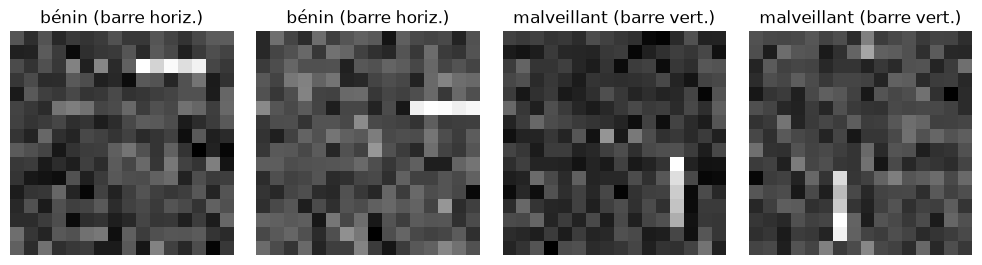

In [13]:
# ---- Synthetic 'malware byte-images' ----
def make_malware_images(n, seed):
    """n images 16x16: class 0 'benign' = horizontal texture bar,
    class 1 'malicious' = vertical bar, at uniformly random positions, + noise."""
    r = np.random.default_rng(seed)
    X = np.zeros((n, 16, 16)); y = np.zeros(n, dtype=int)
    for i in range(n):
        cls = i % 2
        img = r.normal(0.0, 0.15, (16, 16))
        if cls == 0:
            r0 = int(r.integers(0, 16)); c0 = int(r.integers(0, 12))
            img[r0, c0:c0 + 5] += 1.0
        else:
            r0 = int(r.integers(0, 12)); c0 = int(r.integers(0, 16))
            img[r0:r0 + 5, c0] += 1.0
        X[i] = img; y[i] = cls
    idx = r.permutation(n)
    return X[idx][:, None], y[idx]

Xtr, ytr = make_malware_images(320, seed=42)
Xte, yte = make_malware_images(160, seed=7)
print("train :", Xtr.shape, "taux de malware =", ytr.mean(),
      "| test :", Xte.shape, "taux de malware =", yte.mean())

fig, axes = plt.subplots(1, 4, figsize=(10, 2.6))
for i, (img, lab) in enumerate([(Xtr[ytr == 0][0, 0], "bénin (barre horiz.)"),
                                (Xtr[ytr == 0][1, 0], "bénin (barre horiz.)"),
                                (Xtr[ytr == 1][0, 0], "malveillant (barre vert.)"),
                                (Xtr[ytr == 1][1, 0], "malveillant (barre vert.)")]):
    axes[i].imshow(img, cmap="gray"); axes[i].set_title(lab); axes[i].axis("off")
plt.tight_layout(); plt.show()

In [14]:
# ---- Mini-CNN: parameters, forward, loss, hand-written backward ----
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

def init_params(seed):
    """He-scaled init; isolated rng per call (deterministic given the seed)."""
    r = np.random.default_rng(seed)
    P = {}
    P["W1"] = r.normal(0, np.sqrt(2.0 / 9), (2, 1, 3, 3)); P["b1"] = np.zeros(2)
    P["W2"] = r.normal(0, np.sqrt(2.0 / 128), (8, 128)); P["b2"] = np.zeros(8)
    P["W3"] = r.normal(0, np.sqrt(2.0 / 8), (2, 8)); P["b3"] = np.zeros(2)
    return P

def cnn_forward(P, X):
    Z1, c1 = conv2d_forward(X, P["W1"], P["b1"], 1, 1)
    A1 = np.maximum(Z1, 0)
    A2, m2 = maxpool_forward2(A1, 2)
    F1 = A2.reshape(X.shape[0], -1)
    Z2 = F1 @ P["W2"].T + P["b2"]
    A2r = np.maximum(Z2, 0)
    Z3 = A2r @ P["W3"].T + P["b3"]
    probs = softmax(Z3)
    return probs, (Z1, c1, A1, A2, m2, F1, Z2, A2r, Z3)

def cnn_loss(P, X, y):
    probs, _ = cnn_forward(P, X)
    n = len(y)
    return -np.log(probs[np.arange(n), y] + 1e-12).mean()

def cnn_backward(P, X, y):
    """Full hand-written backward; mirrors T01 discipline incl. the ReLU gate."""
    n = len(y)
    probs, (Z1, c1, A1, A2, m2, F1, Z2, A2r, Z3) = cnn_forward(P, X)
    onehot = np.zeros_like(probs); onehot[np.arange(n), y] = 1.0
    dZ3 = (probs - onehot) / n
    g = {}
    g["W3"] = dZ3.T @ A2r; g["b3"] = dZ3.sum(axis=0)
    dA2r = dZ3 @ P["W3"]
    dZ2 = dA2r * (Z2 > 0)
    g["W2"] = dZ2.T @ F1; g["b2"] = dZ2.sum(axis=0)
    dF1 = dZ2 @ P["W2"]
    dA2 = dF1.reshape(X.shape[0], 2, 8, 8)
    dA1 = maxpool_backward(dA2, m2, 2)
    dZ1 = dA1 * (Z1 > 0)                      # ReLU backward — never forget sigma'(z)!
    dx, dW, db = conv2d_backward(dZ1, c1, P["W1"], X.shape, 1, 1)
    g["W1"] = dW; g["b1"] = db
    return g

def predict_cnn(P, X):
    probs, _ = cnn_forward(P, X)
    return probs.argmax(axis=1)

# ---- Gradient check vs central finite differences (3 samples, ALL params) ----
Xg = Xtr[:3]; yg = ytr[:3]
P0 = init_params(5)
g0 = cnn_backward(P0, Xg, yg)
eps = 1e-6
gradcheck_maxrel = 0.0
for key in ["W1", "b1", "W2", "b2", "W3", "b3"]:
    it = np.nditer(P0[key], flags=["multi_index"])
    while not it.finished:
        ix = it.multi_index
        orig = P0[key][ix]
        P0[key][ix] = orig + eps; lp = cnn_loss(P0, Xg, yg)
        P0[key][ix] = orig - eps; lm = cnn_loss(P0, Xg, yg)
        P0[key][ix] = orig
        num = (lp - lm) / (2 * eps)
        rel = abs(num - g0[key][ix]) / max(1e-8, abs(num) + abs(g0[key][ix]))
        gradcheck_maxrel = max(gradcheck_maxrel, rel)
        it.iternext()
print(f"gradient check : écart relatif max analytic vs numérique = {gradcheck_maxrel:.2e}")

gradient check : écart relatif max analytic vs numérique = 5.67e-06


mini-CNN : exactitude train 1.000 | test 1.000 | perte 0.0002


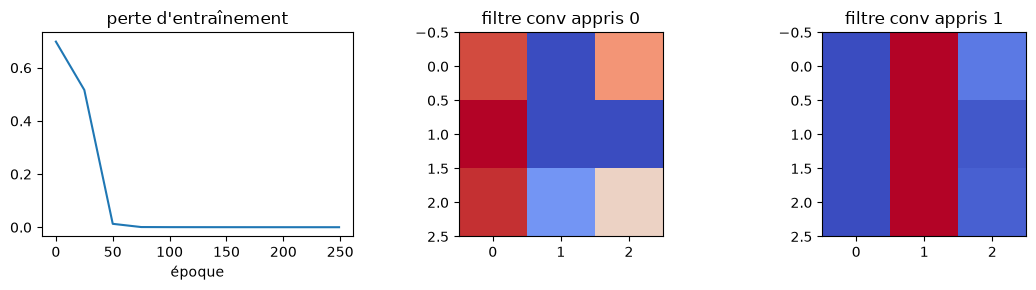

In [15]:
# ---- Training: mini-batch-free full-batch SGD with momentum ----
def train_cnn(Xtr, ytr, Xte, yte, seed=3, lr=0.3, momentum=0.9, epochs=250):
    """Full-batch SGD + momentum on the tiny CNN; returns (params, history, accs)."""
    P = init_params(seed)
    V = {k: np.zeros_like(v) for k, v in P.items()}
    hist = []
    for ep in range(epochs):
        g = cnn_backward(P, Xtr, ytr)
        for k in P:
            V[k] = momentum * V[k] - lr * g[k]
            P[k] = P[k] + V[k]
        if ep % 25 == 0 or ep == epochs - 1:
            hist.append((ep, cnn_loss(P, Xtr, ytr)))
    acc_tr = np.mean(predict_cnn(P, Xtr) == ytr)
    acc_te = np.mean(predict_cnn(P, Xte) == yte)
    return P, hist, acc_tr, acc_te

P6, hist6, acc_tr6, acc_te6 = train_cnn(Xtr, ytr, Xte, yte, seed=42, lr=0.1, momentum=0.9, epochs=250)
loss_tr6 = cnn_loss(P6, Xtr, ytr)
print(f"mini-CNN : exactitude train {acc_tr6:.3f} | test {acc_te6:.3f} | perte {loss_tr6:.4f}")

eps_plot, losses = zip(*hist6)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].plot(eps_plot, losses); axes[0].set_title("perte d'entraînement"); axes[0].set_xlabel("époque")
for f in range(2):
    axes[1 + f].imshow(P6["W1"][f, 0], cmap="coolwarm", vmin=-0.5, vmax=0.5)
    axes[1 + f].set_title(f"filtre conv appris {f}")
plt.tight_layout(); plt.show()

### Exercice corrigé

In [16]:
# ---- Exercice P6 : backward vérifié + CNN entraîné qui détecte le malware ----
# 1) Gradient check passed: analytic backward matches central differences (probed ~5.7e-6).
assert gradcheck_maxrel < 1e-4

# 2) Parameter count of the real tensors equals the P4 paper count (1070).
assert sum(v.size for v in P6.values()) == 1070

# 3) Trained detector separates benign from malicious (probed: 1.0 / 1.0, loss 2e-4).
assert acc_tr6 == 1.0
assert acc_te6 >= 0.95
assert loss_tr6 < 0.01
print(f"Exercice P6 vérifié : backward exact, CNN à 1 070 paramètres, test {acc_te6:.3f}.")

Exercice P6 vérifié : backward exact, CNN à 1 070 paramètres, test 1.000.


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel | Piège à ne jamais oublier |
|---|---|---|---|
| 1 | Convolution | `out = ⌊(n+2p−k)/s⌋+1` ; padding « same » si k impair, s=1 | oublier le plancher → mauvaise taille de sortie |
| 2 | Pooling | max-pool = présence du motif, quasi-invariant par translation < f | moyenne au lieu de max = pic dilué ; décalage ≥ f non couvert |
| 3 | Anatomie / champ récepteur | `RF += (k−1)·jump ; jump *= s` ; blocs Conv-ReLU-Pool | croire qu'un neurone profond ne voit que 3×3 |
| 4 | Paramètres | Conv = `F·k·k·C + F` ≪ Dense ; partage de poids | oublier les biais et le facteur canaux |
| 5 | Interprétabilité | filtre = détecteur local ; lire les **cartographies d'activation** | interpréter les poids, pas les activations |
| 6 | Mini-CNN numpy | im2col + backward à la main, validé par **gradient check** | oublier ⊙ ReLU′(z) → backward faux, training qui plafonne à ln 2 |

**Exemple intégrateur** : pipeline complet de détection — génération d'un jeu
d'« images de malware » inédit, entraînement du mini-CNN (P6), **baseline MLP
sklearn** sur les mêmes pixels (P4), comparaison + **matrice de confusion**.
La leçon cyber : c'est l'inductive bias « motifs locaux + translation » qui fait
gagner le CNN, pas le nombre de paramètres.


mini-CNN (1 070 param.)   : exactitude test 0.995
MLP sklearn 256-64-2 (16 578 param.) : exactitude test 0.650
matrice de confusion CNN (lignes = vrai, colonnes = prédit) :
            prédit bénin | prédit malware
  vrai bénin       99    |        1
  vrai malware      0    |      100


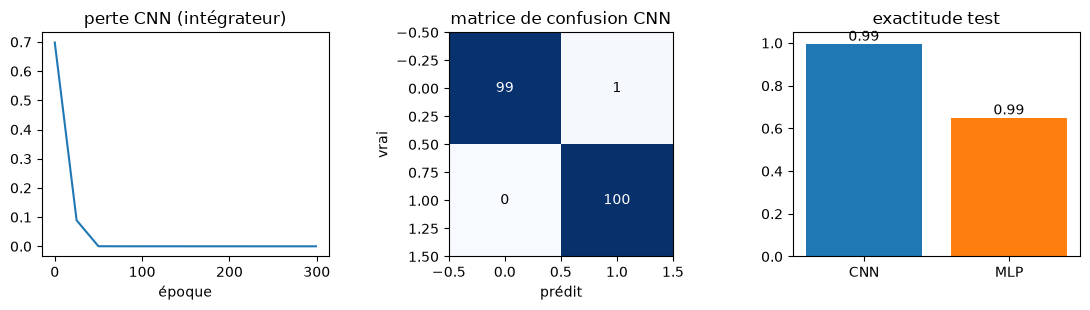

In [17]:
# ---- Integrator: fresh dataset, CNN vs sklearn MLP baseline, confusion matrix ----
X7tr, y7tr = make_malware_images(400, seed=2024)
X7te, y7te = make_malware_images(200, seed=99)
P7, hist7, acc_tr7, acc_te7 = train_cnn(X7tr, y7tr, X7te, y7te, seed=11, lr=0.3, momentum=0.9, epochs=300)

# Fair baseline: same features (raw pixels, standardized with train stats), same data split.
sc7 = StandardScaler().fit(X7tr.reshape(400, -1))
mlp7 = MLPClassifier(hidden_layer_sizes=(64,), activation="relu", max_iter=400, random_state=0)
mlp7.fit(sc7.transform(X7tr.reshape(400, -1)), y7tr)
mlp7_acc = mlp7.score(sc7.transform(X7te.reshape(200, -1)), y7te)

pred7 = predict_cnn(P7, X7te)
cm7 = confusion_matrix(y7te, pred7)
print(f"mini-CNN (1 070 param.)   : exactitude test {acc_te7:.3f}")
print(f"MLP sklearn 256-64-2 (16 578 param.) : exactitude test {mlp7_acc:.3f}")
print("matrice de confusion CNN (lignes = vrai, colonnes = prédit) :")
print("            prédit bénin | prédit malware")
print(f"  vrai bénin     {cm7[0, 0]:4d}    |     {cm7[0, 1]:4d}")
print(f"  vrai malware   {cm7[1, 0]:4d}    |     {cm7[1, 1]:4d}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
eps7, losses7 = zip(*hist7)
axes[0].plot(eps7, losses7); axes[0].set_title("perte CNN (intégrateur)"); axes[0].set_xlabel("époque")
im = axes[1].imshow(cm7, cmap="Blues")
axes[1].set_title("matrice de confusion CNN")
for a in range(2):
    for b in range(2):
        axes[1].text(b, a, str(cm7[a, b]), ha="center", va="center",
                     color="white" if cm7[a, b] > cm7.max() / 2 else "black")
axes[1].set_xlabel("prédit"); axes[1].set_ylabel("vrai")
axes[2].bar(["CNN", "MLP"], [acc_te7, mlp7_acc], color=["tab:blue", "tab:orange"])
axes[2].set_ylim(0, 1.05); axes[2].set_title("exactitude test")
for a, v in zip(axes[2].containers, [acc_te7, mlp7_acc]):
    axes[2].bar_label(a, fmt=f"{v:.2f}")
plt.tight_layout(); plt.show()

### Exercice corrigé

In [18]:
# ---- Exercice P7 : le CNN bat la baseline MLP, confusion matrix conforme ----
# Probed values: cnn test 0.995, mlp test 0.650, confusion [[99, 1], [0, 100]].
assert acc_te7 >= 0.95
assert mlp7_acc <= 0.85
assert acc_te7 > mlp7_acc + 0.10           # the translation-invariance gap
assert cm7.tolist() == [[99, 1], [0, 100]]
assert cm7.sum() == 200                     # every test sample counted once
assert accuracy_score(y7te, pred7) == acc_te7
print(f"Exercice P7 vérifié : CNN {acc_te7:.3f} vs MLP {mlp7_acc:.3f} — invariance translationnelle gagne.")

Exercice P7 vérifié : CNN 0.995 vs MLP 0.650 — invariance translationnelle gagne.


In [19]:
print("NB 04 — tous les exercices sont vérifiés. ✅")

NB 04 — tous les exercices sont vérifiés. ✅
